개념

# 트랜스포머의 등장 배경과 시퀀스 모델의 진화
- 쉬운 비유: 줄 서서 전달하기 vs 다 같이 한 번에 보기
- 기존 RNN: 옆사람에게 귀속말로 한 명씩 차례대로 전달하는 방식입니다. 마지막 사람은 앞의 내용을 잊어버리거나 전달 속도가 너무 느립니다.

- 트랜스포머: 교실 전체에 공지를 띄우듯, 모든 단어를 한 번에 동시에 바라봅니다.

# 실습: "나는 밥을 먹는다" 단어들이 나란히 줄 서는 위치(포지셔널 인코딩)
- 트랜스포머는 단어를 한꺼번에 받기 때문에 '단어의 순서(누가 먼저 나왔는지)'를 알려주는 특별한 번호표(위치 값)를 더해줍니다. 아주 단순한 번호표 부여 방식을 코드로 봅니다.

In [ ]:
!pip install -q transformers torch

In [ ]:
import torch

# 1. 문장 속 단어들 (예: '나는', '밥을', '먹는다')
words = ["나는", "밥을", "먹는다"]
print(f"원래 단어 순서: {words}\n")

# 2. 각 단어의 의미를 담은 가상의 벡터 (임베딩, 여기선 편의상 4차원)
# [의미1, 의미2, 의미3, 의미4]
word_embeddings = torch.tensor([
    [0.1, 0.2, 0.5, 0.1],  # 나는
    [0.9, 0.1, 0.2, 0.4],  # 밥을
    [0.3, 0.8, 0.1, 0.2]   # 먹는다
], dtype=torch.float32)

# 3. 위치 정보를 알려주는 번호표 (포지셔널 인코딩의 아주 단순화된 형태)
position_encodings = torch.tensor([
    [0.0, 1.0, 0.0, 0.0],  # 1번째 위치 표시
    [0.0, 0.0, 1.0, 0.0],  # 2번째 위치 표시
    [0.0, 0.0, 0.0, 1.0]   # 3번째 위치 표시
], dtype=torch.float32)

# 4. 단어 의미 + 위치 번호표를 합치기 (이것이 트랜스포머의 입력이 됨)
transformer_input = word_embeddings + position_encodings

print("--- 단어 의미에 위치 정보가 더해진 최종 입력값 ---")
print(transformer_input)

원래 단어 순서: ['나는', '밥을', '먹는다']

--- 단어 의미에 위치 정보가 더해진 최종 입력값 ---
tensor([[0.1000, 1.2000, 0.5000, 0.1000],
        [0.9000, 0.1000, 1.2000, 0.4000],
        [0.3000, 0.8000, 0.1000, 1.2000]])


# 트랜스포머의 심장: 어텐션(Attention) 메커니즘
- 쉬운 비유: "은행 창구 검색 시스템 (Query, Key, Value)"
1. Query (질문): 내가 찾고 싶은 것 ("사과"라는 단어)

2. Key (목록표): 문장 속 모든 단어들의 명함 ("나는", "사과를", "깎아", "먹었다")

3. Value (실제 내용): 각 단어가 가진 진짜 의미

- 동작: "사과"라는 질문(Query)을 들고 명함(Key)들과 대조해 보니 '깎아'와 '먹었다'라는 단어와 가장 관련이 깊네? 하고 그쪽의 내용(Value)을 집중(Attention)해서 가져오는 원리입니다.

- 실습: 문장에서 단어끼리 서로 얼마나 주목(연관)하는지 계산해보기

In [ ]:
import torch
import torch.nn.functional as F

# 문장의 단어 3개 (Q: 질문, K: 비교 대상 명함)
# 여기서는 컴퓨터가 이해할 수 있는 숫자(벡터)로 표현되어 있다고 가정합니다.
queries = torch.tensor([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]]) # 단어들의 질문
keys = torch.tensor([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])    # 단어들의 명함

# 1. 질문과 명함을 곱해서 서로 얼마나 닮았는지 점수(Score)를 매깁니다.
similarity_scores = torch.matmul(queries, keys.T)
print("1단계: 단어 간 유사도 점수\n", similarity_scores)

# 2. 점수를 확률(합치면 100%)로 바꿔줍니다 (Softmax)
attention_weights = F.softmax(similarity_scores, dim=-1)

print("\n2단계: '어떤 단어에 집중해야 할지' 보여주는 어텐션 확률표")
print(attention_weights)
print("\n(해석: 대각선 숫자가 크다는 것은 자기 자신 및 연관된 단어와의 연관성을 진하게 바라보고 있음을 뜻합니다.)")

1단계: 단어 간 유사도 점수
 tensor([[1., 0., 1.],
        [0., 1., 1.],
        [1., 1., 2.]])

2단계: '어떤 단어에 집중해야 할지' 보여주는 어텐션 확률표
tensor([[0.4223, 0.1554, 0.4223],
        [0.1554, 0.4223, 0.4223],
        [0.2119, 0.2119, 0.5761]])

(해석: 대각선 숫자가 크다는 것은 자기 자신 및 연관된 단어와의 연관성을 진하게 바라보고 있음을 뜻합니다.)


# LLM(대형 언어 모델)으로의 확장 및 활용
- 쉬운 비유: "세계 최고 수준의 무한 글짓기 자동 완성기"
스마트폰 키보드에서 단어를 칠 때 다음 글자를 추천해 주는 기능 기억하시나요? LLM은 이것을 전 세계 인터넷 문서 규모로 엄청나게 키운 것입니다. "오늘 날씨가 정말" 다음에 올 가장 확률이 높은 단어("좋다", "맑다" 등)를 맞히는 게임을 끝없이 반복하며 똑똑해졌습니다.

- 실습: 인공지능이 "다음에 올 글자"를 직접 이어 붙여 문장 만들기
- 오픈소스 초소형 생성형 모델을 이용해 인공지능이 어떻게 글을 만들어내는지 실행해 봅니다.

In [ ]:
from transformers import pipeline

# 전 세계에서 가장 가볍고 유명한 체험용 생성형 AI 모델 불러오기
ai_generator = pipeline('text-generation', model='distilgpt2')

# 인공지능에게 시작 문장 던져주기
my_prompt = "Learning artificial intelligence is"

# AI가 다음 단어를 예측해서 문장 완성하기 (최대 30글자)
result = ai_generator(my_prompt, max_length=30, num_return_sequences=1)

print("--- AI가 스스로 완성한 문장 ---")
print(result[0]['generated_text'])

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'num_return_sequences', 'max_length'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


--- AI가 스스로 완성한 문장 ---
Learning artificial intelligence is a new frontier for artificial intelligence, and it is no surprise that Intel and IBM are now leading the way with the development of artificial intelligence.





The most recent Intel and IBM announcement was that Microsoft and IBM were working closely to create a new operating system called Deep Learning to help them better understand machine learning.

The company is also working with Google to develop artificial intelligence, which it says is a new level of AI.
Image caption Deep learning takes on more of the role of computer science
'Discovery of the true nature of human intelligence'
The company's artificial intelligence research team, based at the University of Michigan, is currently working on a new platform called Deep Learning that will help them analyze and analyze machine learning.
The company has been working with Google, IBM, Google and Microsoft to create Deep Learning that will help them identify and analyze mac

실전)

In [ ]:
!pip install transformers torch matplotlib scikit-learn

# 트랜스포머의 등장 배경과 시퀀스 모델의 진화
# 실습 1: 포지셔널 인코딩(Positional Encoding) 구현 및 시각화

- RNN과 달리 순서 개념이 없는 트랜스포머가 단어의 위치 정보를 인식하기 위해 사용하는 사인/코사인 기반의 포지셔널 인코딩을 시각화합니다.

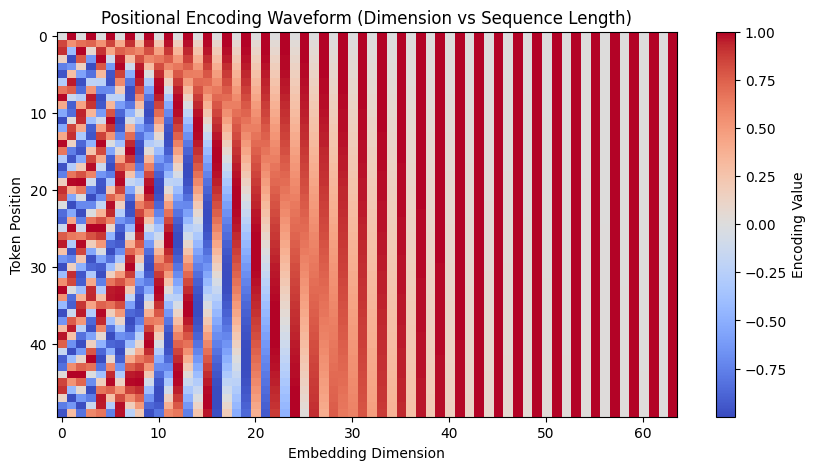

In [ ]:
import torch
import math
import matplotlib.pyplot as plt

class PositionalEncoding(torch.nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x):
        # x shape: [batch_size, seq_len, d_model]
        return x + self.pe[:, :x.size(1)]

# 파라미터 설정 및 실행
d_model = 64
max_len = 50
pe_layer = PositionalEncoding(d_model=d_model, max_len=max_len)
dummy_input = torch.zeros(1, max_len, d_model)
output = pe_layer(dummy_input)

# 시각화
plt.figure(figsize=(10, 5))
plt.imshow(output[0].detach().numpy(), cmap='coolwarm', aspect='auto')
plt.colorbar(label='Encoding Value')
plt.title("Positional Encoding Waveform (Dimension vs Sequence Length)")
plt.xlabel("Embedding Dimension")
plt.ylabel("Token Position")
plt.show()

# 트랜스포머의 심장: 어텐션(Attention) 메커니즘
# 실습 2: 쿼리(Q), 키(K), 밸류(V) 기반 Scaled Dot-Product Attention 직접 구현어텐션
- 수식($Attention(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$)을 파이토치 코드로 구현하여 단어 간 연관성이 계산되는 과정을 확인합니다.

In [ ]:
import torch
import torch.nn.functional as F

def scaled_dot_product_attention(query, key, value, mask=None):
    d_k = query.size(-1)
    # 1. Q와 K^T 행렬곱 후 스케일링
    scores = torch.matmul(query, key.transpose(-2, -1)) / math.sqrt(d_k)

    # 2. 마스크 적용 (선택)
    if mask is not None:
        scores = scores.masked_fill(mask == 0, -1e9)

    # 3. Softmax를 통해 어텐션 가중치(확률) 계산
    attention_weights = F.softmax(scores, dim=-1)

    # 4. Value와 가중치 곱셈
    output = torch.matmul(attention_weights, value)
    return output, attention_weights

# 테스트 데이터 생성 (Batch=1, Seq_len=3, Embedding_dim=4)
torch.manual_seed(42)
Q = torch.randn(1, 3, 4)
K = torch.randn(1, 3, 4)
V = torch.randn(1, 3, 4)

out, weights = scaled_dot_product_attention(Q, K, V)
print("--- Attention Weights (단어 간 연관성 확률) ---")
print(weights)
print("\n--- Output Shape ---")
print(out.shape)

--- Attention Weights (단어 간 연관성 확률) ---
tensor([[[0.3017, 0.3098, 0.3884],
         [0.2451, 0.3801, 0.3748],
         [0.2938, 0.2293, 0.4769]]])

--- Output Shape ---
torch.Size([1, 3, 4])


# LLM(대형 언어 모델)으로의 확장 및 활용
# 실습 3: 허깅페이스(Hugging Face)를 활용한 LLM 텍스트 생성 (GPT 계열)

- 사전 학습된 경량형 디코더 모델을 활용해 프롬프트를 입력했을 때 다음 토큰을 이어 붙여 텍스트를 생성하는 원리를 실습합니다.

In [ ]:
from transformers import pipeline

# 소형 오픈소스 생성 모델 로드 (예: distilgpt2)
generator = pipeline('text-generation', model='distilgpt2')

prompt = "The future of Artificial Intelligence is"
result = generator(prompt, max_length=30, num_return_sequences=1, temperature=0.7)

print("--- LLM 텍스트 생성 결과 ---")
print(result[0]['generated_text'])

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  353MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

...

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'temperature', 'num_return_sequences', 'max_length'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


--- LLM 텍스트 생성 결과 ---
The future of Artificial Intelligence is not a question of economic or political or social problems. It is a question of how to get there. It is a question of how to get there. It is a question of how to get there. It is a question of how to get there. It is a question of how to get there. It is a question of how to get there. It is a question of how to get there. It is a question of how to get there. It is a question of how to get there. It is a question of how to get there. It is a question of how to get there. It is a question of how to get there. It is a question of how to get there. It is a question of how to get there. It is a question of how to get there. It is a question of how to get there. It is a question of how to get there. It is a question of how to get there. It is a question of how to get there. It is a question of how to get there. It is a question of how to get there. It is a question of how to get there. It is a question of how to get there. It 

# 실습 4: 간단한 RAG(검색 증강 생성) 핵심 원리 구현
- LLM의 한계(환각 현상 등)를 보완하기 위해 외부 문서에서 관련 정보를 검색한 뒤 컨텍스트로 제공하는 RAG의 핵심인 유사도 기반 검색을 실습합니다.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 1. 지식베이스(외부 문서 데이터) 구축
documents = [
    "Transformer architecture was introduced in the 2017 paper 'Attention Is All You Need'.",
    "Retrieval-Augmented Generation (RAG) combines external knowledge retrieval with LLMs.",
    "BERT is an encoder-only model designed for bidirectional representation training.",
    "GPT models are decoder-only architectures optimized for autoregressive text generation."
]

# 2. 벡터화 (TF-IDF 이용)
vectorizer = TfidfVectorizer()
doc_embeddings = vectorizer.fit_transform(documents)

# 3. 사용자 질문 입력 및 검색
query = "What is RAG?"
query_embedding = vectorizer.transform([query])

# 4. 코사인 유사도 계산
similarities = cosine_similarity(query_embedding, doc_embeddings).flatten()
best_match_idx = similarities.argmax()

print(f"사용자 질문: {query}\n")
print(f"가장 관련성 높은 검색 문서 (유사도 점수: {similarities[best_match_idx]:.4f}):")
print(documents[best_match_idx])

사용자 질문: What is RAG?

가장 관련성 높은 검색 문서 (유사도 점수: 0.2304):
Retrieval-Augmented Generation (RAG) combines external knowledge retrieval with LLMs.


응용)

In [ ]:
!pip install -q koreanize-matplotlib
import koreanize_matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 32.0 MB/s eta 0:00:00


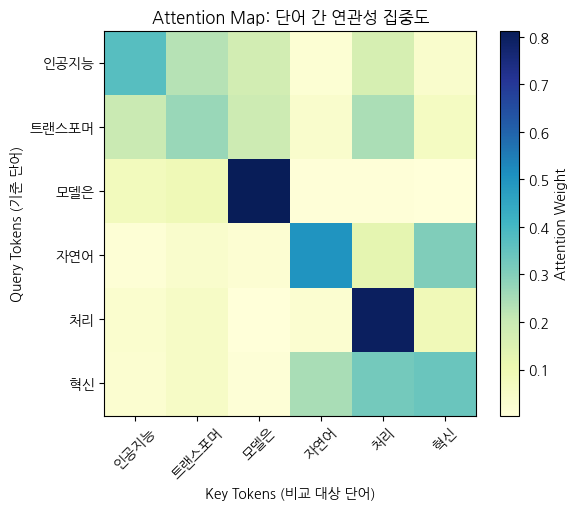

In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# 1. 문장 속 단어 정의 (예시: "인공지능 트랜스포머 모델은 자연어 처리의 혁신이다")
# 분석하고자 하는 문장을 형태소나 단어 단위로 쪼갠 토큰 리스트를 생성합니다.
tokens = ["인공지능", "트랜스포머", "모델은", "자연어", "처리", "혁신"]
seq_len = len(tokens) # 문장에 포함된 총 단어(토큰)의 개수 (6개)

# 2. 임의의 단어 벡터(의미) 생성 (Seq_len=6, Dim=4)
# 실제 모델에서는 학습된 임베딩 값을 사용하지만, 여기서는 직관적 이해를 위해
# 6개의 단어가 각각 4차원의 숫자(의미)를 가지도록 무작위(Random) 벡터를 생성합니다.
torch.seed()
embeddings = torch.randn(seq_len, 4)

# 3. Query, Key, Value 설정
# 셀프 어텐션(Self-Attention)의 핵심 개념인 Q(질문), K(비교 대상 명함)를 정의합니다.
# 여기서는 편의상 단어 자체의 임베딩 값을 질문과 명함으로 동시에 사용합니다.
Q = embeddings
K = embeddings

# 4. Scaled Dot-Product Attention 계산
# 어텐션 공식: Attention(Q, K, V) = softmax((Q * K^T) / sqrt(d_k)) * V
d_k = Q.size(-1) # 단어 벡터의 차원 수 (여기서는 4)

# (1) Q와 K의 전치행렬(K.T)을 곱해 모든 단어 간의 유사도 점수(Score)를 계산합니다.
# (2) 벡터 차원 수의 제곱근(sqrt(d_k))으로 나누어 값의 크기를 안정화(Scaling)합니다.
scores = torch.matmul(Q, K.T) / (d_k ** 0.5)

# (3) Softmax 함수를 적용하여 점수들을 확률(합이 1이 되는 비율)로 변환합니다.
# .detach().numpy()를 통해 PyTorch 텐서를 시각화 라이브러리(Matplotlib)가 읽을 수 있는 NumPy 배열로 바꿉니다.
attention_weights = F.softmax(scores, dim=-1).detach().numpy()

# 5. 시각화 (어텐션 맵)
# 계산된 어텐션 가중치(확률)를 히트맵(Heatmap) 형태로 시각화하여 어떤 단어끼리 강하게 연관되어 있는지 확인합니다.
plt.figure(figsize=(6, 5))
plt.imshow(attention_weights, cmap='YlGnBu', aspect='auto') # 색상이 진할수록 연관성이 높음
plt.colorbar(label='Attention Weight') # 우측에 색상 범례 추가

# X축과 Y축에 미리 정의한 단어 토큰(tokens)을 라벨로 지정합니다.
plt.xticks(ticks=range(seq_len), labels=tokens, rotation=45)
plt.yticks(ticks=range(seq_len), labels=tokens)

# 그래프 제목과 축 이름을 설정합니다.
plt.title("Attention Map: 단어 간 연관성 집중도")
plt.xlabel("Key Tokens (비교 대상 단어)")
plt.ylabel("Query Tokens (기준 단어)")

# 완성된 그래프를 화면에 출력합니다.
plt.show()

In [ ]:
from transformers import pipeline

# 1. 소형 생성형 LLM 로드 (distilgpt2)
# Hugging Face의 pipeline을 사용하여 사전 학습된 텍스트 생성 모델인 'distilgpt2'를 불러옵니다.
generator = pipeline('text-generation', model='distilgpt2')

# 2. 일상적이고 명확한 문맥 프롬프트 작성
# AI가 문맥을 이어받아 자연스럽게 글을 생성할 수 있도록 시작이 되는 영어 문장(프롬프트)을 정의합니다.
prompt = "The key to learning programming is consistency and "

# 3. AI가 다음 내용을 이어 쓰도록 설정
# generator 함수에 프롬프트를 전달하여 모델이 뒤이어 나올 텍스트를 생성하도록 지시합니다.
result = generator(
    prompt,
    max_new_tokens=100,           # AI가 생성할 최대 토큰(단어/조각) 개수를 100개로 넉넉하게 지정합니다.
    temperature=0.7,              # 값이 높을수록 창의적이고 다양한 문장이 나오고, 낮을수록 정석적인 단어가 선택됩니다. (적당한 균형 유지)
    num_return_sequences=1,       # 생성할 결과물의 개수를 1개로 지정합니다.
    pad_token_id=generator.tokenizer.eos_token_id  # 문장이 끝날 때 패딩 토큰과 문장 종료 토큰(EOS)이 충돌하지 않도록 지정합니다.
)

# 4. 결과 정리 및 출력
# 생성된 결과 리스트에서 첫 번째 결과물 내부의 전체 텍스트를 가져옵니다.
generated_text = result[0]['generated_text']

# 전체 텍스트에서 우리가 입력했던 원본 프롬프트 부분을 제외하고, AI가 새로 이어 붙인 뒷부분만 잘라냅니다.
predicted_continuation = generated_text[len(prompt):].strip()

# 터미널 창에 입력 프롬프트, AI가 이어 쓴 내용, 그리고 전체 완성된 문장을 차례대로 출력합니다.
print("--- 텍스트 자동 완성 응용 결과 ---")
print(f"입력 프롬프트: {prompt}")
print(f"AI가 이어 붙인 내용: {predicted_continuation}")
print(f"\n전체 완성된 문장:\n{generated_text}")

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=100) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


--- 텍스트 자동 완성 응용 결과 ---
입력 프롬프트: The key to learning programming is consistency and 
AI가 이어 붙인 내용: vernacular. It›s a pretty heavy lifting and it›s a lot of work for you.



You can see that the ›s have to be as deep as possible to understand the language. But if you›ve been playing with the language, you›ve also had to learn that it›s completely different from the other languages. For example, if you›ve been playing with the language, you›ve also had to

전체 완성된 문장:
The key to learning programming is consistency and vernacular. It›s a pretty heavy lifting and it›s a lot of work for you.



You can see that the ›s have to be as deep as possible to understand the language. But if you›ve been playing with the language, you›ve also had to learn that it›s completely different from the other languages. For example, if you›ve been playing with the language, you›ve also had to


미니 GPT

In [ ]:
# ============================================================
# Mini GPT 구현 Part 1
#
# 구성:
# 1. Library Import
# 2. Mini Dataset 생성
# 3. Character Tokenizer 구현
# 4. Next Token Prediction 학습 데이터 생성
#
# 목적:
# - GPT의 기본 학습 방식 이해
# - 이전 Token을 기반으로 다음 Token 예측 구조 이해
#
# GPT 기본 흐름:
#
# Text
#  ↓
# Tokenizer
#  ↓
# Token ID
#  ↓
# Transformer 입력
#
# ============================================================


# ============================================================
# 1. Library Import
# ============================================================

# PyTorch 기반 Neural Network 구현
import torch
import torch.nn as nn

# Loss 계산 및 Softmax 등 함수 사용
import torch.nn.functional as F



# ============================================================
# 2. Mini Dataset 생성
# ============================================================
#
# 실제 GPT는 대규모 Corpus를 사용하지만,
# 여기서는 Transformer 학습 흐름 확인을 위해
# 작은 문자 데이터 사용
#
# 학습 목표:
#
# "hello" 다음에는 어떤 Token이 올 확률이 높은가?
#
# ============================================================

text = """
hello world
hello ai
hello transformer
hello gpt
"""


# 데이터에 존재하는 모든 문자 추출
# GPT에서는 Vocabulary 생성 과정에 해당

chars = sorted(set(text))


# Vocabulary 크기

vocab_size = len(chars)


print("Vocabulary:", chars)
print("Vocabulary Size:", vocab_size)



# ============================================================
# 3. Character Tokenizer 구현
# ============================================================
#
# 역할:
# - 문자를 숫자 Token ID로 변환
# - Model은 문자열을 직접 처리하지 못하므로
#   숫자 형태의 입력 필요
#
# 예:
#
# "hello"
#
# ↓
#
# [7,4,8,8,9]
#
# ============================================================


# 문자 -> Token ID 변환 Dictionary

stoi =


# Token ID -> 문자 변환 Dictionary

itos =



# Encoding 함수
# 역할:
# 문자열을 Token ID 리스트로 변환

def encode(text):
    return



# Decoding 함수
# 역할:
# Token ID 리스트를 원래 문자열로 복원

def decode(tokens):
    return



# 전체 Text를 Token 데이터로 변환

data =


print("\nEncoded Data")
print(data[:20])



# ============================================================
# 4. Next Token Prediction Dataset 생성
# ============================================================
#
# GPT 학습 방식:
#
# 입력:
# "hello worl"
#
# 정답:
# "ello world"
#
#
# 현재 Token을 보고
# 다음 Token을 예측하는 방식
#
# ============================================================


# Transformer가 한번에 처리할 Token 길이

block_size = 16


# 입력 Token
# 현재 위치까지의 문장

x = data[:block_size]


# 정답 Token
# 한 칸 이동한 다음 Token

y = data[1:block_size+1]



print("\nInput Token")
print(decode(x.tolist()))


print("\nTarget Token")
print(decode(y.tolist()))


print("\nInput Tensor")
print(x)


print("\nTarget Tensor")
print(y)

Vocabulary: ['\n', ' ', 'a', 'd', 'e', 'f', 'g', 'h', 'i', 'l', 'm', 'n', 'o', 'p', 'r', 's', 't', 'w']
Vocabulary Size: 18

Encoded Data
tensor([ 0,  7,  4,  9,  9, 12,  1, 17, 12, 14,  9,  3,  0,  7,  4,  9,  9, 12,
         1,  2])

Input Token

hello world
hel

Target Token
hello world
hell

Input Tensor
tensor([ 0,  7,  4,  9,  9, 12,  1, 17, 12, 14,  9,  3,  0,  7,  4,  9])

Target Tensor
tensor([ 7,  4,  9,  9, 12,  1, 17, 12, 14,  9,  3,  0,  7,  4,  9,  9])


In [ ]:
# ============================================================
# Mini GPT 구현 Part 2
#
# 구성:
# 1. Positional Encoding
# 2. Masked Self Attention
# 3. Transformer Decoder Block
#
# 목적:
# - GPT Transformer Decoder 구조 이해
# - Self Attention을 통한 Token 관계 학습 이해
#
# GPT 구조:
#
# Token Embedding
#       +
# Position Embedding
#       ↓
# Masked Self Attention
#       ↓
# Feed Forward Network
#       ↓
# Transformer Block
#
# ============================================================



# ============================================================
# 1. Positional Encoding
# ============================================================
#
# 역할:
# - Transformer는 Token 순서 정보를 알 수 없음
# - 위치 정보를 Embedding으로 추가
#
# 예:
#
# hello
# 0 1 2 3 4
#
# ============================================================


class PositionalEncoding(nn.Module):

    def __init__(self, dim, max_len=100):
        super().__init__()
        self.embedding =


    def forward(self, x):
        B, T =
        positions =
        return self.embedding(positions)



# ============================================================
# 2. Masked Self Attention
# ============================================================
#
# 역할:
# - GPT 핵심 Attention 구조
# - 현재 Token은 이전 Token만 참고
#
# Causal Mask:
#
# 1 0 0
# 1 1 0
# 1 1 1
#
# 미래 Token 접근 차단
#
# ============================================================


class SelfAttention(nn.Module):

    def __init__(self, dim):
        super().__init__()
        self.qkv = nn.Linear(dim, dim * 3)
        self.output = nn.Linear(dim, dim)


    def forward(self, x):

        B, T, C = x.shape

        # Query, Key, Value 생성




        # Query와 Key 기반 Attention Score 계산




        # 미래 Token 참조 방지 Mask 생성

        mask =


        attention = a


        # Attention 확률 계산

        attention =


        # Value와 Attention 결합

        return self.output(attention @ v)



# ============================================================
# 3. Transformer Decoder Block
# ============================================================
#
# 역할:
# - GPT Decoder Layer 구성
#
# 구조:
#
# LayerNorm
#    ↓
# Self Attention
#    ↓
# Residual
#    ↓
# Feed Forward
#    ↓
# Residual
#
# ============================================================


class TransformerBlock(nn.Module):

    def __init__(self, dim):
        super().__init__()

        # Self Attention Layer

        self.attention =

        # Normalization Layer

        self.norm1 =


        # Feed Forward Network
        #
        # Transformer 내부 비선형 변환 담당

        self.ffn =


        # 두 번째 Normalization

        self.norm2 =



    def forward(self, x):

        # Attention + Residual Connection

        x =


        # Feed Forward + Residual Connection

        x =

        return x

In [ ]:
# ============================================================
# Mini GPT 구현 Part 3
#
# 구성:
# 1. Mini GPT Model 생성
# 2. Training Loop
# 3. Text Generation
#
# 목적:
# - Transformer Decoder 기반 LLM 완성
# - Next Token Prediction 학습 및 생성 과정 이해
#
# GPT 전체 흐름:
#
# Token ID
#    ↓
# Token Embedding
#    +
# Position Embedding
#    ↓
# Transformer Block
#    ↓
# Linear Layer
#    ↓
# Next Token Probability
#    ↓
# Text Generation
#
# ============================================================



# ============================================================
# 1. Mini GPT Model
# ============================================================
#
# 역할:
# - Embedding
# - Transformer Block
# - Output Layer
#
# 을 연결하여 Language Model 구성
#
# ============================================================


class MiniGPT(nn.Module):

    def __init__(self, vocab_size, dim=64):
        super().__init__()

        # Token ID → Vector 변환

        self.token_embedding =


        # Token 위치 정보 추가

        self.position_embedding =


        # Transformer Decoder Block

        self.block =



        # Hidden Vector → Vocabulary Score 변환

        self.lm_head =



    def forward(self, x):

        # Token Embedding 생성

        token =


        # Position Embedding 생성

        position =


        # Token + Position 결합

        x = token + position


        # Transformer Block 통과

        x = self.block(x)


        # 다음 Token 확률 계산용 출력

        return self.lm_head(x)




# ============================================================
# 2. Model 생성 및 Optimizer 설정
# ============================================================


model =


# Transformer 학습에 많이 사용하는 Optimizer

optimizer =




# ============================================================
# 3. Training Loop
# ============================================================
#
# 역할:
# - 입력 Token(x)을 이용하여
#   다음 Token(y)을 예측하도록 학습
#
# Loss:
# Cross Entropy
#
# ============================================================


for epoch in range(500):

    # Forward 실행

    logits =



    # 예측 결과와 실제 Token 비교

    loss =


    # Gradient 초기화




    # Backpropagation

    loss.backward()


    # Parameter 업데이트

    optimizer.step()


    if epoch % 100 == 0:
        print(f"Epoch:{epoch}, Loss:{loss.item()}")



# ============================================================
# 4. Text Generation
# ============================================================
#
# 역할:
# - 학습된 GPT 모델로 다음 Token 반복 생성
#
# 과정:
#
# 입력:
# hello
#
# 예측:
# hello w
#
# 반복:
# hello world
#
# ============================================================


def generate(model, start, length=20):

    # 추론 모드 전환

    model.eval()


    # 시작 문장을 Token 변환

    tokens =



    # Token 반복 생성

    for _ in range(length):

        # 현재 Token 기반 다음 Token 예측

        logits = model(tokens)


        # 마지막 위치의 가장 높은 확률 Token 선택

        next_token =



        # 예측 Token 추가

        tokens =



    # Token ID → Text 변환

    return decode(tokens[0].tolist())



# ============================================================
# 5. Generation Test
# ============================================================


result = generate(model, "hello")


print("\nGenerated Text")
print(result)

Epoch:0, Loss:3.0290615558624268
Epoch:100, Loss:0.0013513993471860886
Epoch:200, Loss:0.000616242818068713
Epoch:300, Loss:0.0003507277288008481
Epoch:400, Loss:0.0002270844706799835

Generated Text
hello  world
helllllld
he


의미있는 학습을 했다고 판